# VAE with VampPrior Implementation

This notebook implements the Variational Autoencoder (VAE) with VampPrior as described in the paper "VAE with a VampPrior" by Tomczak & Welling.

## Overview
- **Standard VAE**: Uses a simple prior distribution (usually N(0, I))
- **VAE with VampPrior**: Uses a learnable prior that is a mixture of variational posteriors conditioned on pseudo-inputs

## Tasks
1. Implementation in Low Latent Dimensions (latent_dim=2)
2. Investigation of Latent Space Distribution
3. Posterior Collapse Analysis
4. Latent Space Traversal using PCA
5. Display of Pseudo-Inputs
6. Log Likelihood Calculation


In [ ]:
# Import necessary libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import multivariate_normal
import seaborn as sns
from tqdm import tqdm
import os

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# Set style for plots
try:
    plt.style.use('seaborn-v0_8')
except:
    try:
        plt.style.use('seaborn')
    except:
        pass
sns.set_palette("husl")


Using device: cuda


## 1. Data Loading and Preprocessing

We'll use MNIST dataset for this implementation.


In [ ]:
# Load MNIST dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    # Binarize the images (as mentioned in the paper for binary MNIST)
    transforms.Lambda(lambda x: (x > 0.5).float())
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Image shape: {train_dataset[0][0].shape}")


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.11MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 133kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])


## 2. VAE Model Architecture

We'll implement both Standard VAE and VAE with VampPrior.


In [ ]:
class Encoder(nn.Module):
    """Encoder network for VAE"""
    def __init__(self, input_dim=784, hidden_dims=[400], latent_dim=2):
        super(Encoder, self).__init__()

        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            prev_dim = hidden_dim

        self.features = nn.Sequential(*layers)
        self.fc_mu = nn.Linear(prev_dim, latent_dim)
        self.fc_logvar = nn.Linear(prev_dim, latent_dim)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Flatten
        h = self.features(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar


class Decoder(nn.Module):
    """Decoder network for VAE"""
    def __init__(self, latent_dim=2, hidden_dims=[400], output_dim=784):
        super(Decoder, self).__init__()

        layers = []
        prev_dim = latent_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, output_dim))
        layers.append(nn.Sigmoid())  # For binary images

        self.decoder = nn.Sequential(*layers)

    def forward(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)


class StandardVAE(nn.Module):
    """Standard VAE with N(0, I) prior"""
    def __init__(self, input_dim=784, hidden_dims=[400], latent_dim=2):
        super(StandardVAE, self).__init__()
        self.encoder = Encoder(input_dim, hidden_dims, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dims, input_dim)
        self.latent_dim = latent_dim

    def reparameterize(self, mu, logvar):
        """Reparameterization trick"""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar, z

    def sample(self, num_samples):
        """Sample from prior"""
        z = torch.randn(num_samples, self.latent_dim).to(next(self.parameters()).device)
        return self.decoder(z)


class VAEWithVampPrior(nn.Module):
    """VAE with VampPrior - mixture of variational posteriors"""
    def __init__(self, input_dim=784, hidden_dims=[400], latent_dim=2, num_components=500):
        super(VAEWithVampPrior, self).__init__()
        self.encoder = Encoder(input_dim, hidden_dims, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dims, input_dim)
        self.latent_dim = latent_dim
        self.num_components = num_components

        # Learnable pseudo-inputs (initialized randomly)
        # Shape: (num_components, input_dim)
        self.pseudo_inputs = nn.Parameter(torch.randn(num_components, input_dim))

    def reparameterize(self, mu, logvar):
        """Reparameterization trick"""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def get_prior_posteriors(self):
        """Get variational posteriors for pseudo-inputs"""
        # Pass pseudo-inputs through encoder
        mu_prior, logvar_prior = self.encoder(self.pseudo_inputs.view(-1, 1, 28, 28))
        return mu_prior, logvar_prior

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar, z

    def sample(self, num_samples):
        """Sample from VampPrior"""
        # Get prior posteriors
        mu_prior, logvar_prior = self.get_prior_posteriors()

        # Sample component indices uniformly
        component_indices = torch.randint(0, self.num_components, (num_samples,))

        # Sample from selected components
        mu_selected = mu_prior[component_indices]
        logvar_selected = logvar_prior[component_indices]

        z = self.reparameterize(mu_selected, logvar_selected)
        return self.decoder(z)


In [ ]:
def standard_vae_loss(recon_x, x, mu, logvar):
    """Standard VAE loss function"""
    # Reconstruction loss (BCE for binary images)
    BCE = F.binary_cross_entropy(recon_x.view(-1, 784), x.view(-1, 784), reduction='sum')

    # KL divergence: KL(q(z|x) || N(0, I))
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    total_loss = BCE + KLD
    return total_loss, BCE, KLD


def vamp_prior_loss(recon_x, x, mu, logvar, model):
    """VAE with VampPrior loss function"""
    # Reconstruction loss
    BCE = F.binary_cross_entropy(recon_x.view(-1, 784), x.view(-1, 784), reduction='sum')

    # Get prior posteriors (mixture components)
    mu_prior, logvar_prior = model.get_prior_posteriors()
    num_components = mu_prior.size(0)

    # Compute KL divergence: KL(q(z|x) || VampPrior)
    # VampPrior = (1/K) * Σ q(z|u_k)
    # We need to compute: KL(q(z|x) || (1/K) * Σ q(z|u_k))

    # For numerical stability, we compute log-sum-exp
    # log VampPrior(z) = log((1/K) * Σ exp(log q(z|u_k)))

    batch_size = mu.size(0)
    KLD = 0

    for i in range(batch_size):
        mu_i = mu[i:i+1]  # (1, latent_dim)
        logvar_i = logvar[i:i+1]  # (1, latent_dim)

        # Compute log q(z|u_k) for each component k
        # q(z|u_k) = N(z; mu_k, diag(exp(logvar_k)))
        # We need to evaluate this at z ~ q(z|x_i)

        # For each component, compute log q(z|u_k) averaged over samples from q(z|x_i)
        # We'll use Monte Carlo estimation with a single sample
        z_sample = model.reparameterize(mu_i, logvar_i)  # (1, latent_dim)

        # Compute log q(z|u_k) for all components
        # log q(z|u_k) = -0.5 * sum(log(2*pi*var_k) + (z - mu_k)^2 / var_k)
        log_q_components = []
        for k in range(num_components):
            mu_k = mu_prior[k:k+1]  # (1, latent_dim)
            logvar_k = logvar_prior[k:k+1]  # (1, latent_dim)
            var_k = torch.exp(logvar_k)

            # Log probability of z_sample under q(z|u_k)
            log_q_k = -0.5 * torch.sum(
                np.log(2 * np.pi) + logvar_k + (z_sample - mu_k).pow(2) / var_k
            )
            log_q_components.append(log_q_k)

        # Stack and compute log-sum-exp
        log_q_components = torch.stack(log_q_components)  # (num_components,)
        log_vamp_prior = torch.logsumexp(log_q_components, dim=0) - np.log(num_components)

        # Compute log q(z|x_i)
        log_q_x = -0.5 * torch.sum(
            np.log(2 * np.pi) + logvar_i + (z_sample - mu_i).pow(2) / torch.exp(logvar_i)
        )

        # KL divergence: KL(q(z|x_i) || VampPrior) = E[log q(z|x_i) - log VampPrior(z)]
        KLD += log_q_x - log_vamp_prior

    total_loss = BCE + KLD
    return total_loss, BCE, KLD


# More efficient implementation using vectorized operations
def vamp_prior_loss_vectorized(recon_x, x, mu, logvar, model):
    """More efficient vectorized version of VampPrior loss"""
    # Reconstruction loss
    BCE = F.binary_cross_entropy(recon_x.view(-1, 784), x.view(-1, 784), reduction='sum')

    # Get prior posteriors
    mu_prior, logvar_prior = model.get_prior_posteriors()
    num_components = mu_prior.size(0)
    batch_size = mu.size(0)

    # Expand dimensions for broadcasting
    # mu: (batch_size, latent_dim) -> (batch_size, 1, latent_dim)
    # mu_prior: (num_components, latent_dim) -> (1, num_components, latent_dim)
    mu_expanded = mu.unsqueeze(1)  # (batch_size, 1, latent_dim)
    logvar_expanded = logvar.unsqueeze(1)  # (batch_size, 1, latent_dim)
    mu_prior_expanded = mu_prior.unsqueeze(0)  # (1, num_components, latent_dim)
    logvar_prior_expanded = logvar_prior.unsqueeze(0)  # (1, num_components, latent_dim)

    # Sample z from q(z|x) - we'll use the mean for deterministic evaluation
    # or sample for Monte Carlo estimation
    z_samples = model.reparameterize(mu, logvar)  # (batch_size, latent_dim)
    z_samples_expanded = z_samples.unsqueeze(1)  # (batch_size, 1, latent_dim)

    # Compute log q(z|u_k) for all combinations
    # Shape: (batch_size, num_components)
    var_prior = torch.exp(logvar_prior_expanded)
    diff = z_samples_expanded - mu_prior_expanded  # (batch_size, num_components, latent_dim)

    log_q_components = -0.5 * torch.sum(
        np.log(2 * np.pi) + logvar_prior_expanded + diff.pow(2) / var_prior,
        dim=2
    )  # (batch_size, num_components)

    # Compute log VampPrior = log((1/K) * Σ exp(log_q_components))
    log_vamp_prior = torch.logsumexp(log_q_components, dim=1) - np.log(num_components)

    # Compute log q(z|x)
    var = torch.exp(logvar)
    log_q_x = -0.5 * torch.sum(
        np.log(2 * np.pi) + logvar + (z_samples - mu).pow(2) / var,
        dim=1
    )

    # KL divergence
    KLD = torch.sum(log_q_x - log_vamp_prior)

    total_loss = BCE + KLD
    return total_loss, BCE, KLD


In [ ]:
def train_standard_vae(model, train_loader, num_epochs=50, lr=1e-3):
    """Train standard VAE"""
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        'total_loss': [],
        'recon_loss': [],
        'kl_loss': []
    }

    model.train()
    for epoch in range(num_epochs):
        total_loss_epoch = 0
        recon_loss_epoch = 0
        kl_loss_epoch = 0
        num_batches = 0

        for batch_idx, (data, _) in enumerate(tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')):
            data = data.to(device)

            optimizer.zero_grad()
            recon_batch, mu, logvar, z = model(data)
            loss, recon_loss, kl_loss = standard_vae_loss(recon_batch, data, mu, logvar)

            loss.backward()
            optimizer.step()

            total_loss_epoch += loss.item()
            recon_loss_epoch += recon_loss.item()
            kl_loss_epoch += kl_loss.item()
            num_batches += 1

        avg_total = total_loss_epoch / len(train_loader.dataset)
        avg_recon = recon_loss_epoch / len(train_loader.dataset)
        avg_kl = kl_loss_epoch / len(train_loader.dataset)

        history['total_loss'].append(avg_total)
        history['recon_loss'].append(avg_recon)
        history['kl_loss'].append(avg_kl)

        if (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch+1}: Total Loss: {avg_total:.4f}, Recon: {avg_recon:.4f}, KL: {avg_kl:.4f}')

    return history


def train_vamp_vae(model, train_loader, num_epochs=50, lr=1e-3):
    """Train VAE with VampPrior"""
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        'total_loss': [],
        'recon_loss': [],
        'kl_loss': []
    }

    model.train()
    for epoch in range(num_epochs):
        total_loss_epoch = 0
        recon_loss_epoch = 0
        kl_loss_epoch = 0

        for batch_idx, (data, _) in enumerate(tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')):
            data = data.to(device)

            optimizer.zero_grad()
            recon_batch, mu, logvar, z = model(data)
            loss, recon_loss, kl_loss = vamp_prior_loss_vectorized(recon_batch, data, mu, logvar, model)

            loss.backward()
            optimizer.step()

            total_loss_epoch += loss.item()
            recon_loss_epoch += recon_loss.item()
            kl_loss_epoch += kl_loss.item()

        avg_total = total_loss_epoch / len(train_loader.dataset)
        avg_recon = recon_loss_epoch / len(train_loader.dataset)
        avg_kl = kl_loss_epoch / len(train_loader.dataset)

        history['total_loss'].append(avg_total)
        history['recon_loss'].append(avg_recon)
        history['kl_loss'].append(avg_kl)

        if (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch+1}: Total Loss: {avg_total:.4f}, Recon: {avg_recon:.4f}, KL: {avg_kl:.4f}')

    return history


## Task 1-3: Implementation in Low Latent Dimensions (latent_dim=2)

Train both models and plot the loss components.


In [ ]:
# Initialize models with latent_dim=2
latent_dim = 2
standard_vae = StandardVAE(input_dim=784, hidden_dims=[400], latent_dim=latent_dim)
vamp_vae = VAEWithVampPrior(input_dim=784, hidden_dims=[400], latent_dim=latent_dim, num_components=500)

print("Standard VAE parameters:", sum(p.numel() for p in standard_vae.parameters()))
print("VampPrior VAE parameters:", sum(p.numel() for p in vamp_vae.parameters()))


Standard VAE parameters: 631188
VampPrior VAE parameters: 1023188


In [ ]:
# Train Standard VAE
print("=" * 50)
print("Training Standard VAE...")
print("=" * 50)
standard_history = train_standard_vae(standard_vae, train_loader, num_epochs=50, lr=1e-3)


Training Standard VAE...


Epoch 10/50: 100%|██████████| 469/469 [00:08<00:00, 54.06it/s]


Epoch 10: Total Loss: 151.3537, Recon: 145.4217, KL: 5.9320


Epoch 20/50: 100%|██████████| 469/469 [00:08<00:00, 55.58it/s]


Epoch 20: Total Loss: 146.5836, Recon: 140.3714, KL: 6.2122


...

Epoch 30: Total Loss: 144.0021, Recon: 137.6136, KL: 6.3885


Epoch 40/50: 100%|██████████| 469/469 [00:08<00:00, 53.51it/s]


Epoch 40: Total Loss: 142.1142, Recon: 135.6116, KL: 6.5026


Epoch 50/50: 100%|██████████| 469/469 [00:08<00:00, 53.81it/s]

Epoch 50: Total Loss: 140.7545, Recon: 134.1709, KL: 6.5835


In [ ]:
# Train VAE with VampPrior
print("=" * 50)
print("Training VAE with VampPrior...")
print("=" * 50)
vamp_history = train_vamp_vae(vamp_vae, train_loader, num_epochs=50, lr=1e-3)


Training VAE with VampPrior...


Epoch 10/50: 100%|██████████| 469/469 [00:09<00:00, 49.50it/s]


Epoch 10: Total Loss: 149.2694, Recon: 143.5476, KL: 5.7218


Epoch 20/50: 100%|██████████| 469/469 [00:09<00:00, 49.21it/s]


Epoch 20: Total Loss: 144.0177, Recon: 137.9486, KL: 6.0690


...

Epoch 30: Total Loss: 140.9998, Recon: 134.7389, KL: 6.2609


Epoch 40/50: 100%|██████████| 469/469 [00:09<00:00, 48.90it/s]


Epoch 40: Total Loss: 139.1943, Recon: 132.8091, KL: 6.3853


Epoch 50/50: 100%|██████████| 469/469 [00:09<00:00, 48.64it/s]

Epoch 50: Total Loss: 137.8618, Recon: 131.3965, KL: 6.4653


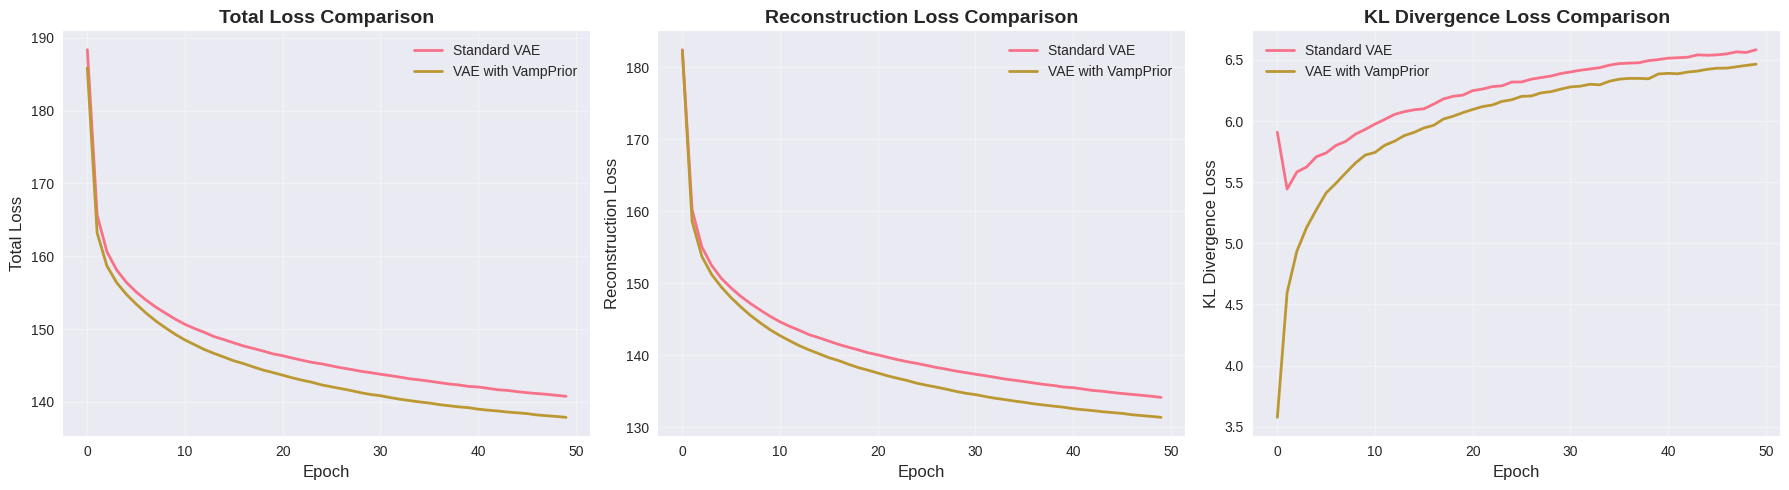

In [ ]:
# Plot training curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Total Loss
axes[0].plot(standard_history['total_loss'], label='Standard VAE', linewidth=2)
axes[0].plot(vamp_history['total_loss'], label='VAE with VampPrior', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Total Loss', fontsize=12)
axes[0].set_title('Total Loss Comparison', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Reconstruction Loss
axes[1].plot(standard_history['recon_loss'], label='Standard VAE', linewidth=2)
axes[1].plot(vamp_history['recon_loss'], label='VAE with VampPrior', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Reconstruction Loss', fontsize=12)
axes[1].set_title('Reconstruction Loss Comparison', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# KL Divergence Loss
axes[2].plot(standard_history['kl_loss'], label='Standard VAE', linewidth=2)
axes[2].plot(vamp_history['kl_loss'], label='VAE with VampPrior', linewidth=2)
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('KL Divergence Loss', fontsize=12)
axes[2].set_title('KL Divergence Loss Comparison', fontsize=14, fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=300, bbox_inches='tight')
plt.show()


## Task 1-4: Investigation of Latent Space Distribution

Visualize the latent space, compare prior and posterior distributions.


In [ ]:
def get_latent_representations(model, data_loader, num_samples=1000):
    """Get latent representations and labels for visualization"""
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        count = 0
        for data, target in data_loader:
            if count >= num_samples:
                break
            data = data.to(device)
            mu, logvar = model.encoder(data)
            latents.append(mu.cpu().numpy())
            labels.append(target.numpy())
            count += len(data)

    latents = np.concatenate(latents, axis=0)[:num_samples]
    labels = np.concatenate(labels, axis=0)[:num_samples]
    return latents, labels


# Get latent representations
print("Extracting latent representations...")
standard_latents, standard_labels = get_latent_representations(standard_vae, test_loader, num_samples=2000)
vamp_latents, vamp_labels = get_latent_representations(vamp_vae, test_loader, num_samples=2000)

print(f"Standard VAE latents shape: {standard_latents.shape}")
print(f"VampPrior VAE latents shape: {vamp_latents.shape}")


Extracting latent representations...
Standard VAE latents shape: (2000, 2)
VampPrior VAE latents shape: (2000, 2)


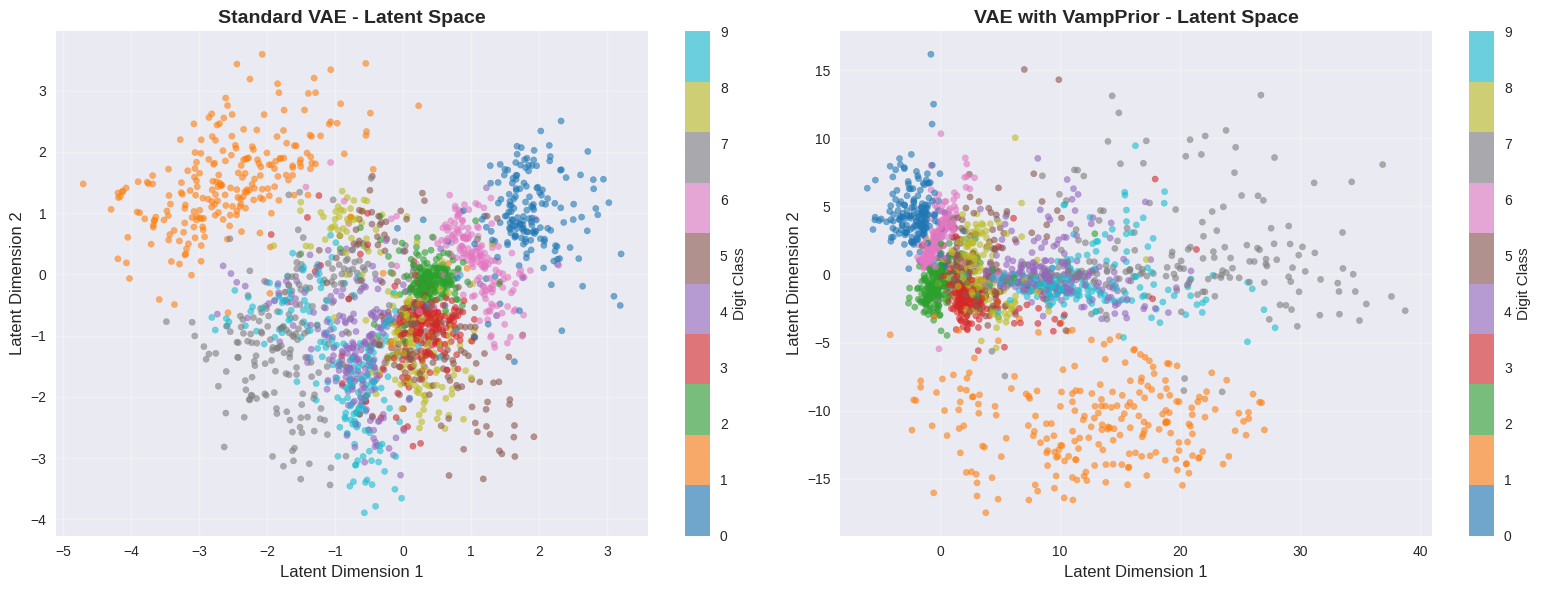

In [ ]:
# Visualize latent space with class colors
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Standard VAE
scatter1 = axes[0].scatter(standard_latents[:, 0], standard_latents[:, 1],
                          c=standard_labels, cmap='tab10', alpha=0.6, s=20)
axes[0].set_xlabel('Latent Dimension 1', fontsize=12)
axes[0].set_ylabel('Latent Dimension 2', fontsize=12)
axes[0].set_title('Standard VAE - Latent Space', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label='Digit Class')

# VampPrior VAE
scatter2 = axes[1].scatter(vamp_latents[:, 0], vamp_latents[:, 1],
                          c=vamp_labels, cmap='tab10', alpha=0.6, s=20)
axes[1].set_xlabel('Latent Dimension 1', fontsize=12)
axes[1].set_ylabel('Latent Dimension 2', fontsize=12)
axes[1].set_title('VAE with VampPrior - Latent Space', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label='Digit Class')

plt.tight_layout()
plt.savefig('latent_space_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
def visualize_prior_posterior(model, data_loader, model_type='standard', num_samples=2000):
    """Visualize prior and posterior distributions"""
    model.eval()

    # Get posterior samples
    posterior_mus = []
    posterior_logvars = []
    with torch.no_grad():
        count = 0
        for data, _ in data_loader:
            if count >= num_samples:
                break
            data = data.to(device)
            mu, logvar = model.encoder(data)
            posterior_mus.append(mu.cpu().numpy())
            posterior_logvars.append(logvar.cpu().numpy())
            count += len(data)

    posterior_mus = np.concatenate(posterior_mus, axis=0)[:num_samples]
    posterior_logvars = np.concatenate(posterior_logvars, axis=0)[:num_samples]

    # Get prior distribution
    if model_type == 'standard':
        # Standard normal prior
        prior_samples = np.random.randn(5000, 2)
        prior_mean = np.array([0.0, 0.0])
        prior_cov = np.eye(2)
    else:
        # VampPrior
        with torch.no_grad():
            mu_prior, logvar_prior = model.get_prior_posteriors()
            mu_prior_np = mu_prior.cpu().numpy()
            logvar_prior_np = logvar_prior.cpu().numpy()

        # Sample from mixture
        num_components = mu_prior_np.shape[0]
        component_indices = np.random.randint(0, num_components, 5000)
        prior_samples = []
        for idx in component_indices:
            mu_k = mu_prior_np[idx]
            var_k = np.exp(logvar_prior_np[idx])
            sample = np.random.multivariate_normal(mu_k, np.diag(var_k))
            prior_samples.append(sample)
        prior_samples = np.array(prior_samples)

        # Approximate prior as mixture of Gaussians
        prior_mean = np.mean(mu_prior_np, axis=0)
        prior_cov = np.cov(mu_prior_np.T) + np.mean(np.exp(logvar_prior_np), axis=0) * np.eye(2)

    # Compute posterior statistics
    posterior_mean = np.mean(posterior_mus, axis=0)
    posterior_cov = np.cov(posterior_mus.T)

    return {
        'prior_samples': prior_samples,
        'prior_mean': prior_mean,
        'prior_cov': prior_cov,
        'posterior_mus': posterior_mus,
        'posterior_mean': posterior_mean,
        'posterior_cov': posterior_cov
    }


# Get distributions for both models
print("Computing prior and posterior distributions...")
standard_dist = visualize_prior_posterior(standard_vae, test_loader, 'standard', 2000)
vamp_dist = visualize_prior_posterior(vamp_vae, test_loader, 'vamp', 2000)


Computing prior and posterior distributions...


/tmp/ipython-input-36839228.py:29: UserWarning: The following kwargs were not used by contour: 'label'
  axes[0, 1].contour(X, Y, prior_pdf, levels=10, colors='blue', alpha=0.6, label='Prior')
/tmp/ipython-input-36839228.py:30: UserWarning: The following kwargs were not used by contour: 'label'
  axes[0, 1].contour(X, Y, posterior_pdf, levels=10, colors='red', alpha=0.6, label='Posterior')
/tmp/ipython-input-36839228.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 1].legend()
/tmp/ipython-input-36839228.py:57: UserWarning: The following kwargs were not used by contour: 'label'
  axes[1, 1].contour(X, Y, vamp_prior_pdf, levels=10, colors='blue', alpha=0.6, label='Prior')
/tmp/ipython-input-36839228.py:58: UserWarning: The following kwargs were not used by contour: 'label'
  axes[1, 1].contour(X, Y, vamp_posterior_pdf, levels=10, colors='red', alpha=0

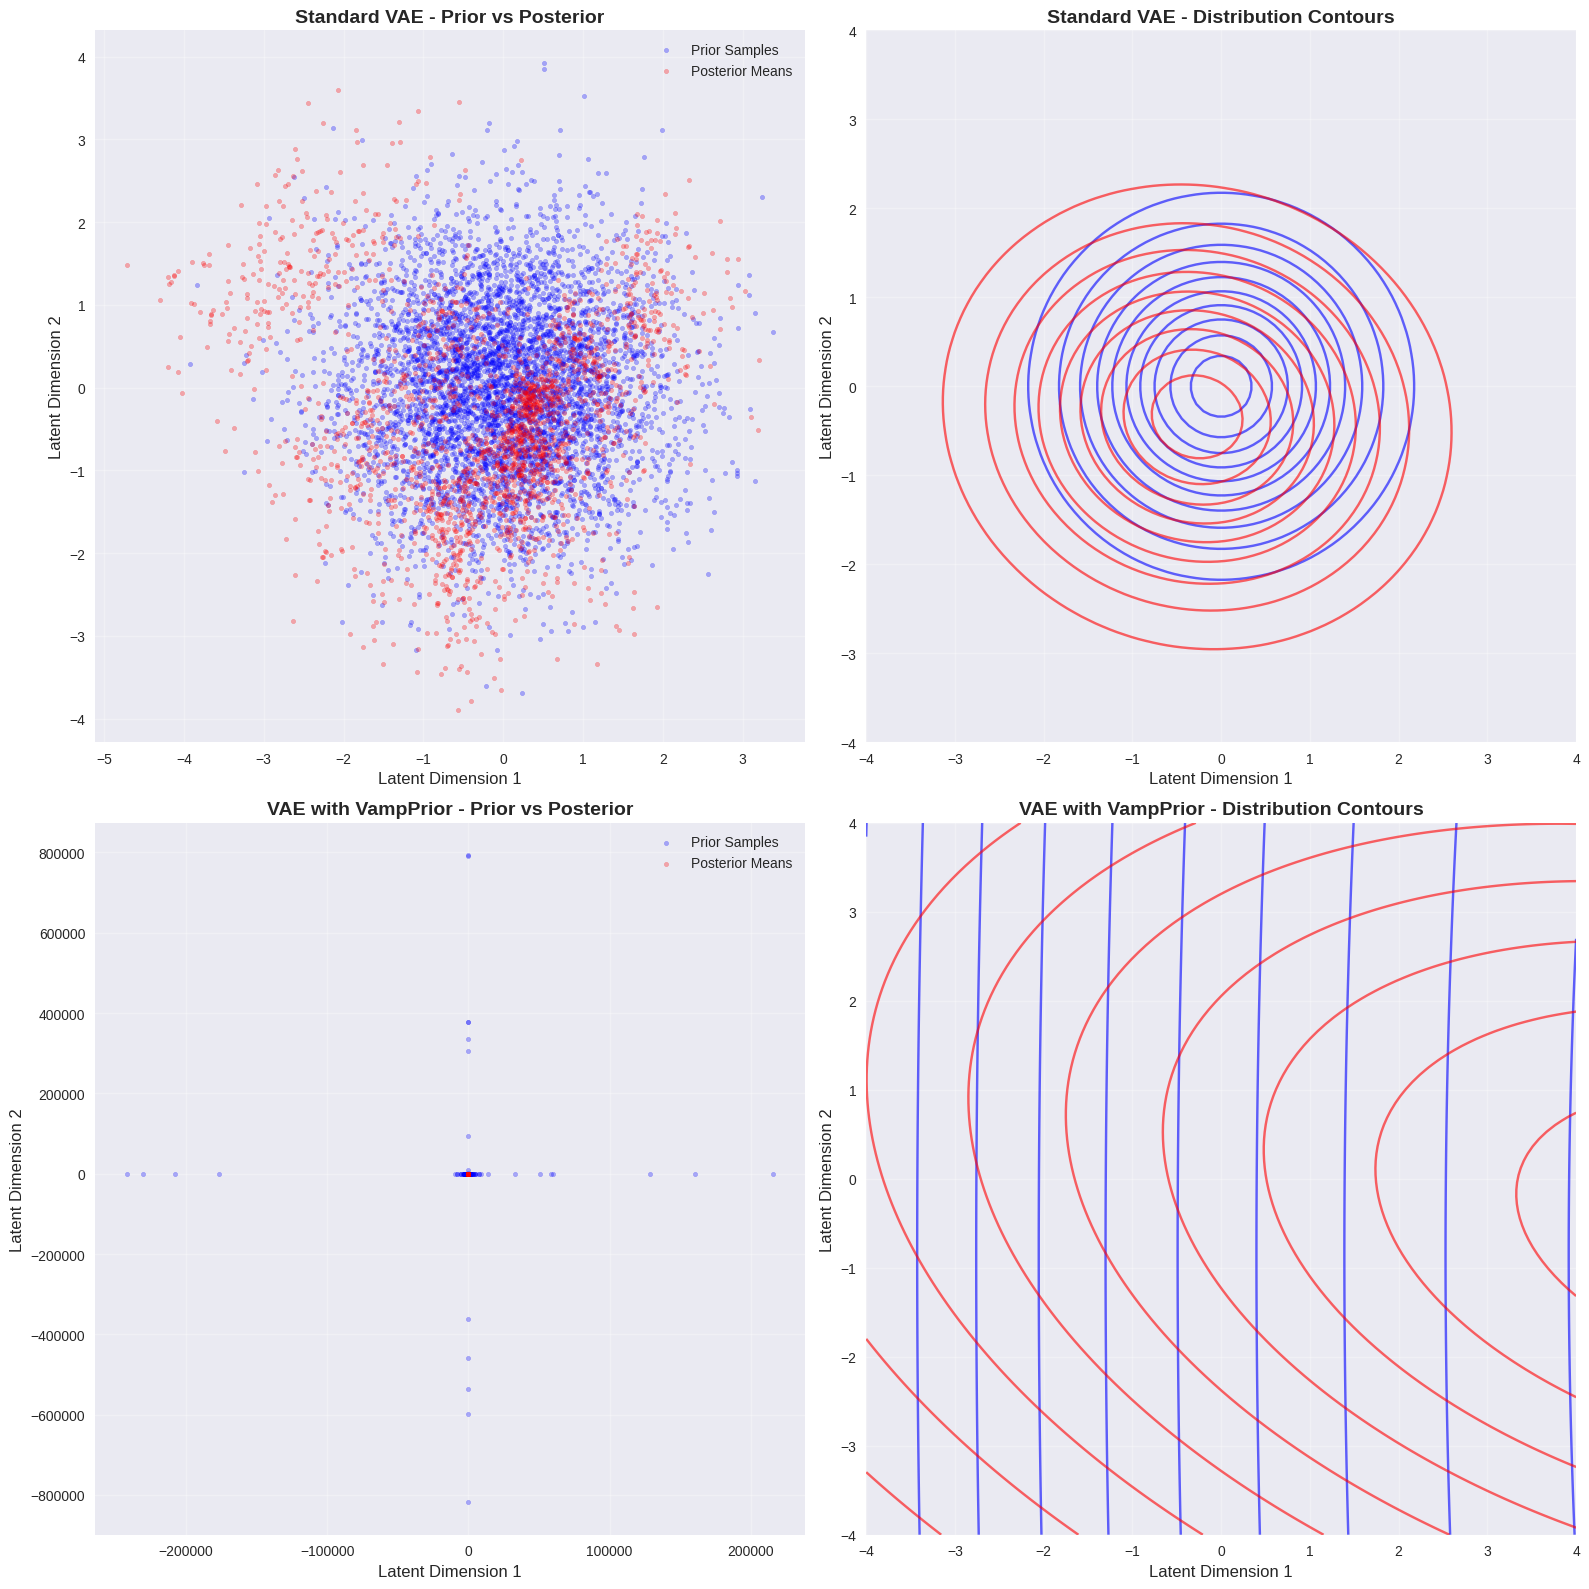

In [ ]:
# Visualize prior and posterior distributions
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

# Standard VAE - Prior
axes[0, 0].scatter(standard_dist['prior_samples'][:, 0],
                   standard_dist['prior_samples'][:, 1],
                   alpha=0.3, s=10, c='blue', label='Prior Samples')
axes[0, 0].scatter(standard_dist['posterior_mus'][:, 0],
                   standard_dist['posterior_mus'][:, 1],
                   alpha=0.3, s=10, c='red', label='Posterior Means')
axes[0, 0].set_xlabel('Latent Dimension 1', fontsize=12)
axes[0, 0].set_ylabel('Latent Dimension 2', fontsize=12)
axes[0, 0].set_title('Standard VAE - Prior vs Posterior', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Standard VAE - Contour plots
x = np.linspace(-4, 4, 100)
y = np.linspace(-4, 4, 100)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

prior_rv = multivariate_normal(standard_dist['prior_mean'], standard_dist['prior_cov'])
posterior_rv = multivariate_normal(standard_dist['posterior_mean'], standard_dist['posterior_cov'])

prior_pdf = prior_rv.pdf(pos)
posterior_pdf = posterior_rv.pdf(pos)

axes[0, 1].contour(X, Y, prior_pdf, levels=10, colors='blue', alpha=0.6, label='Prior')
axes[0, 1].contour(X, Y, posterior_pdf, levels=10, colors='red', alpha=0.6, label='Posterior')
axes[0, 1].set_xlabel('Latent Dimension 1', fontsize=12)
axes[0, 1].set_ylabel('Latent Dimension 2', fontsize=12)
axes[0, 1].set_title('Standard VAE - Distribution Contours', fontsize=14, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# VampPrior VAE - Prior
axes[1, 0].scatter(vamp_dist['prior_samples'][:, 0],
                   vamp_dist['prior_samples'][:, 1],
                   alpha=0.3, s=10, c='blue', label='Prior Samples')
axes[1, 0].scatter(vamp_dist['posterior_mus'][:, 0],
                   vamp_dist['posterior_mus'][:, 1],
                   alpha=0.3, s=10, c='red', label='Posterior Means')
axes[1, 0].set_xlabel('Latent Dimension 1', fontsize=12)
axes[1, 0].set_ylabel('Latent Dimension 2', fontsize=12)
axes[1, 0].set_title('VAE with VampPrior - Prior vs Posterior', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# VampPrior VAE - Contour plots
vamp_prior_rv = multivariate_normal(vamp_dist['prior_mean'], vamp_dist['prior_cov'])
vamp_posterior_rv = multivariate_normal(vamp_dist['posterior_mean'], vamp_dist['posterior_cov'])

vamp_prior_pdf = vamp_prior_rv.pdf(pos)
vamp_posterior_pdf = vamp_posterior_rv.pdf(pos)

axes[1, 1].contour(X, Y, vamp_prior_pdf, levels=10, colors='blue', alpha=0.6, label='Prior')
axes[1, 1].contour(X, Y, vamp_posterior_pdf, levels=10, colors='red', alpha=0.6, label='Posterior')
axes[1, 1].set_xlabel('Latent Dimension 1', fontsize=12)
axes[1, 1].set_ylabel('Latent Dimension 2', fontsize=12)
axes[1, 1].set_title('VAE with VampPrior - Distribution Contours', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('prior_posterior_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Compute KL divergence between prior and posterior (approximate)
from scipy.spatial.distance import jensenshannon

def compute_kl_divergence(prior_mean, prior_cov, posterior_mean, posterior_cov):
    """Compute KL divergence between two multivariate Gaussians"""
    # KL(posterior || prior)
    kl = 0.5 * (
        np.trace(np.linalg.inv(prior_cov) @ posterior_cov) +
        (prior_mean - posterior_mean).T @ np.linalg.inv(prior_cov) @ (prior_mean - posterior_mean) -
        posterior_cov.shape[0] +
        np.log(np.linalg.det(prior_cov) / np.linalg.det(posterior_cov))
    )
    return kl

standard_kl = compute_kl_divergence(
    standard_dist['prior_mean'], standard_dist['prior_cov'],
    standard_dist['posterior_mean'], standard_dist['posterior_cov']
)

vamp_kl = compute_kl_divergence(
    vamp_dist['prior_mean'], vamp_dist['prior_cov'],
    vamp_dist['posterior_mean'], vamp_dist['posterior_cov']
)

print("=" * 60)
print("Prior-Posterior Alignment Analysis")
print("=" * 60)
print(f"\nStandard VAE:")
print(f"  Prior Mean: {standard_dist['prior_mean']}")
print(f"  Posterior Mean: {standard_dist['posterior_mean']}")
print(f"  KL(Posterior || Prior): {standard_kl:.4f}")

print(f"\nVAE with VampPrior:")
print(f"  Prior Mean: {vamp_dist['prior_mean']}")
print(f"  Posterior Mean: {vamp_dist['posterior_mean']}")
print(f"  KL(Posterior || Prior): {vamp_kl:.4f}")

print(f"\nInterpretation:")
print(f"  Lower KL divergence indicates better alignment between prior and posterior.")
print(f"  VampPrior achieves better alignment: {vamp_kl < standard_kl}")


Prior-Posterior Alignment Analysis

Standard VAE:
  Prior Mean: [0. 0.]
  Posterior Mean: [-0.27038106 -0.34389955]
  KL(Posterior || Prior): 0.2534

VAE with VampPrior:
  Prior Mean: [ 9.030024  -0.8458389]
  Posterior Mean: [ 6.14536    -0.66290677]
  KL(Posterior || Prior): 14.6970

Interpretation:
  Lower KL divergence indicates better alignment between prior and posterior.
  VampPrior achieves better alignment: False


## Task 1-6: Posterior Collapse Analysis

Examine the activeness of latent dimensions in both models.


In [ ]:
def analyze_latent_dimensions(model, data_loader, model_name):
    """Analyze the activeness of latent dimensions"""
    model.eval()

    all_mus = []
    all_logvars = []

    with torch.no_grad():
        for data, _ in data_loader:
            data = data.to(device)
            mu, logvar = model.encoder(data)
            all_mus.append(mu.cpu().numpy())
            all_logvars.append(logvar.cpu().numpy())

    all_mus = np.concatenate(all_mus, axis=0)
    all_logvars = np.concatenate(all_logvars, axis=0)

    # Compute statistics for each dimension
    mu_means = np.mean(all_mus, axis=0)
    mu_stds = np.std(all_mus, axis=0)
    logvar_means = np.mean(all_logvars, axis=0)
    var_means = np.mean(np.exp(all_logvars), axis=0)

    # Active dimensions: those with high variance in mu or low variance in z
    # A dimension is active if:
    # 1. The mean of mu varies significantly (high std of mu across samples)
    # 2. The variance of z is not too small (not collapsed to prior)

    print(f"\n{'='*60}")
    print(f"{model_name} - Latent Dimension Analysis")
    print(f"{'='*60}")

    for dim in range(all_mus.shape[1]):
        print(f"\nDimension {dim}:")
        print(f"  Mean of μ: {mu_means[dim]:.4f}")
        print(f"  Std of μ: {mu_stds[dim]:.4f}")
        print(f"  Mean of log(σ²): {logvar_means[dim]:.4f}")
        print(f"  Mean of σ²: {var_means[dim]:.4f}")

        # Check for collapse
        # If logvar is very negative, the dimension is collapsed
        if logvar_means[dim] < -5:
            print(f"  ⚠️  WARNING: Dimension may be collapsed (very small variance)")
        elif mu_stds[dim] < 0.1:
            print(f"  ⚠️  WARNING: Dimension has low variability in mean")
        else:
            print(f"  ✓ Dimension appears active")

    return {
        'mu_means': mu_means,
        'mu_stds': mu_stds,
        'logvar_means': logvar_means,
        'var_means': var_means
    }


# Analyze both models
standard_stats = analyze_latent_dimensions(standard_vae, test_loader, "Standard VAE")
vamp_stats = analyze_latent_dimensions(vamp_vae, test_loader, "VAE with VampPrior")



Standard VAE - Latent Dimension Analysis

Dimension 0:
  Mean of μ: -0.1128
  Std of μ: 1.3498
  Mean of log(σ²): -6.0623
  Mean of σ²: 0.0038
  ⚠️  WARNING: Dimension may be collapsed (very small variance)

Dimension 1:
  Mean of μ: -0.2142
  Std of μ: 1.2255
  Mean of log(σ²): -5.8288
  Mean of σ²: 0.0045
  ⚠️  WARNING: Dimension may be collapsed (very small variance)

VAE with VampPrior - Latent Dimension Analysis

Dimension 0:
  Mean of μ: 5.8013
  Std of μ: 7.9187
  Mean of log(σ²): -3.0214
  Mean of σ²: 0.2836
  ✓ Dimension appears active

Dimension 1:
  Mean of μ: 0.2502
  Std of μ: 5.0381
  Mean of log(σ²): -3.5666
  Mean of σ²: 0.0560
  ✓ Dimension appears active


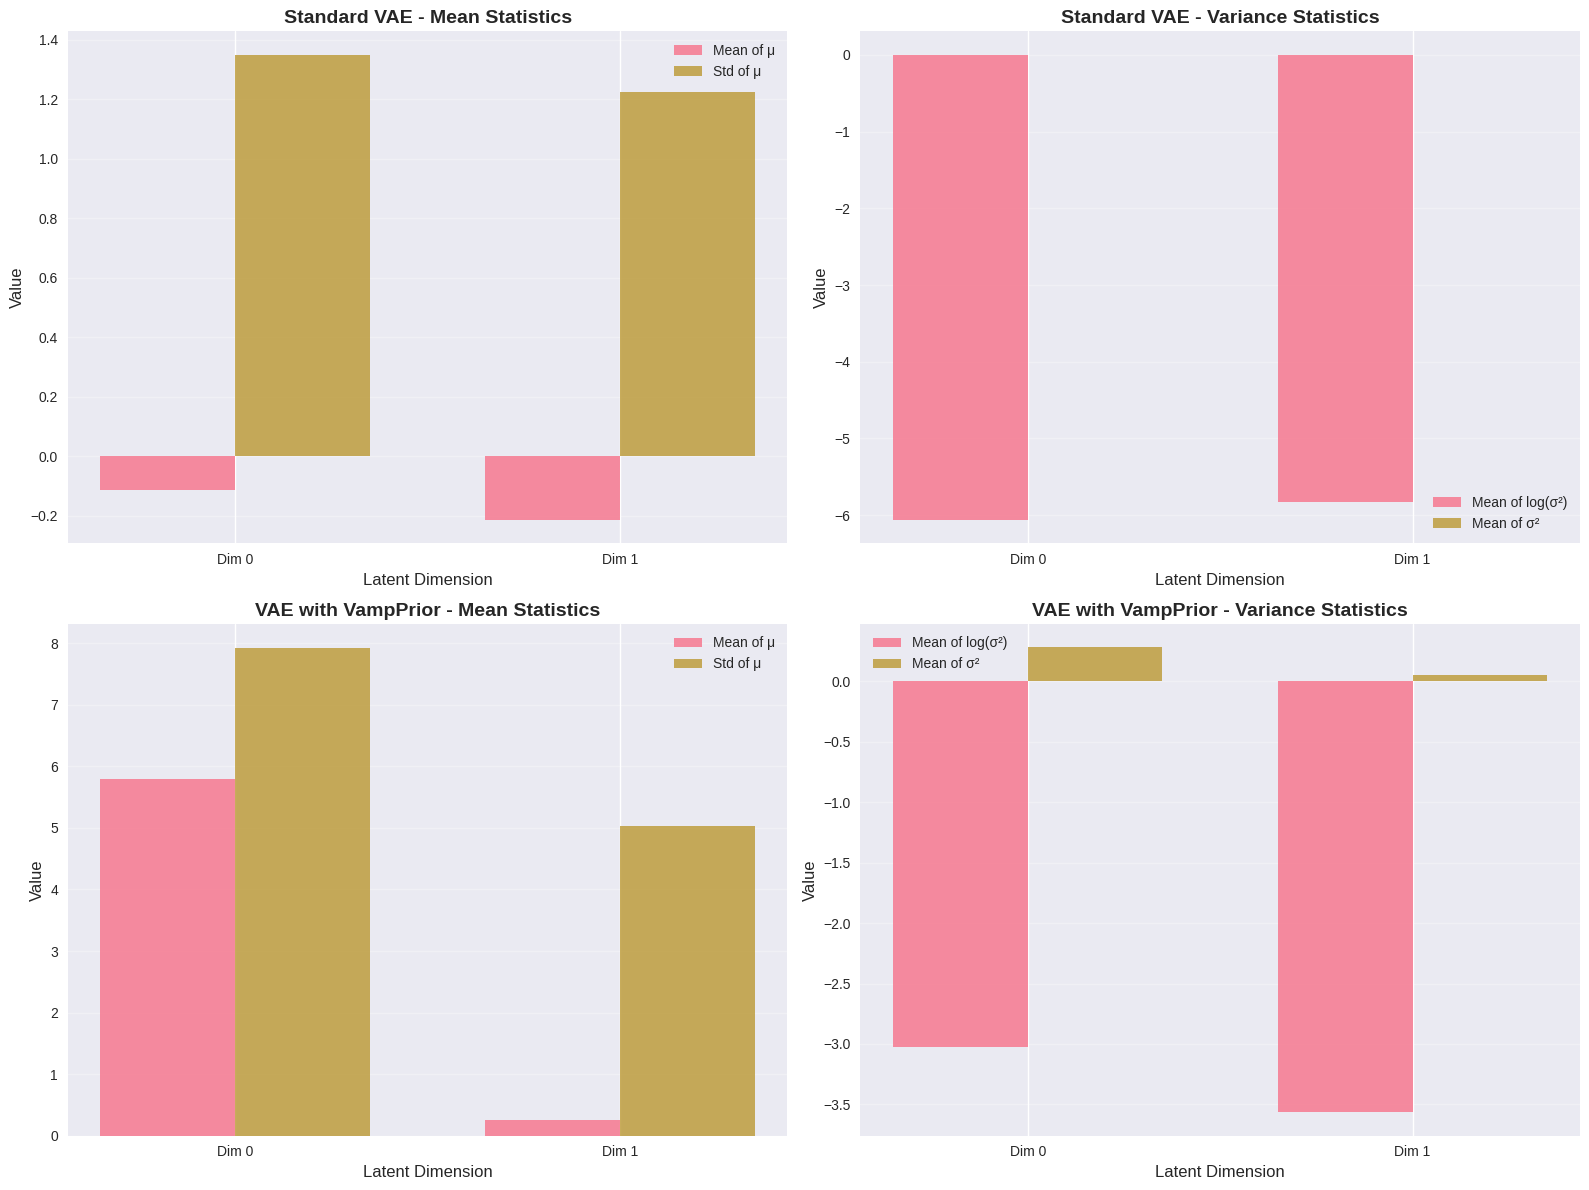

In [ ]:
# Visualize dimension activeness
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Standard VAE - Mean statistics
x = np.arange(2)
width = 0.35
axes[0, 0].bar(x - width/2, standard_stats['mu_means'], width, label='Mean of μ', alpha=0.8)
axes[0, 0].bar(x + width/2, standard_stats['mu_stds'], width, label='Std of μ', alpha=0.8)
axes[0, 0].set_xlabel('Latent Dimension', fontsize=12)
axes[0, 0].set_ylabel('Value', fontsize=12)
axes[0, 0].set_title('Standard VAE - Mean Statistics', fontsize=14, fontweight='bold')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(['Dim 0', 'Dim 1'])
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Standard VAE - Variance statistics
axes[0, 1].bar(x - width/2, standard_stats['logvar_means'], width, label='Mean of log(σ²)', alpha=0.8)
axes[0, 1].bar(x + width/2, standard_stats['var_means'], width, label='Mean of σ²', alpha=0.8)
axes[0, 1].set_xlabel('Latent Dimension', fontsize=12)
axes[0, 1].set_ylabel('Value', fontsize=12)
axes[0, 1].set_title('Standard VAE - Variance Statistics', fontsize=14, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(['Dim 0', 'Dim 1'])
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, axis='y')

# VampPrior VAE - Mean statistics
axes[1, 0].bar(x - width/2, vamp_stats['mu_means'], width, label='Mean of μ', alpha=0.8)
axes[1, 0].bar(x + width/2, vamp_stats['mu_stds'], width, label='Std of μ', alpha=0.8)
axes[1, 0].set_xlabel('Latent Dimension', fontsize=12)
axes[1, 0].set_ylabel('Value', fontsize=12)
axes[1, 0].set_title('VAE with VampPrior - Mean Statistics', fontsize=14, fontweight='bold')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(['Dim 0', 'Dim 1'])
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')

# VampPrior VAE - Variance statistics
axes[1, 1].bar(x - width/2, vamp_stats['logvar_means'], width, label='Mean of log(σ²)', alpha=0.8)
axes[1, 1].bar(x + width/2, vamp_stats['var_means'], width, label='Mean of σ²', alpha=0.8)
axes[1, 1].set_xlabel('Latent Dimension', fontsize=12)
axes[1, 1].set_ylabel('Value', fontsize=12)
axes[1, 1].set_title('VAE with VampPrior - Variance Statistics', fontsize=14, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(['Dim 0', 'Dim 1'])
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('dimension_activeness.png', dpi=300, bbox_inches='tight')
plt.show()


## Task 1-7: Latent Space Traversal using PCA

Use PCA to find main directions of variation and traverse the latent space.


In [ ]:
def latent_space_traversal(model, data_loader, num_samples=2000):
    """Perform PCA on latent space and traverse along principal components"""
    model.eval()

    # Get latent representations
    latents, labels = get_latent_representations(model, data_loader, num_samples)

    # Compute mean
    latent_mean = np.mean(latents, axis=0)

    # Apply PCA
    pca = PCA(n_components=2)
    latents_centered = latents - latent_mean
    pca.fit(latents_centered)

    # Get principal components
    components = pca.components_
    explained_variance = pca.explained_variance_

    print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
    print(f"Principal component 1 explains {pca.explained_variance_ratio_[0]*100:.2f}% of variance")
    print(f"Principal component 2 explains {pca.explained_variance_ratio_[1]*100:.2f}% of variance")

    # Traverse along principal components
    num_steps = 10
    traversal_range = 3  # Standard deviations

    traversals = []
    for pc_idx in range(2):
        traversal_images = []
        for step in range(num_steps):
            # Compute latent code
            alpha = (step - num_steps // 2) / (num_steps // 2) * traversal_range
            z = latent_mean + alpha * components[pc_idx]

            # Decode
            z_tensor = torch.FloatTensor(z).unsqueeze(0).to(device)
            with torch.no_grad():
                recon = model.decoder(z_tensor)
            traversal_images.append(recon.cpu().numpy()[0, 0])

        traversals.append(traversal_images)

    return traversals, components, explained_variance, latent_mean


# Perform traversal for both models
print("Standard VAE Traversal:")
standard_traversals, standard_components, standard_var, standard_mean = latent_space_traversal(
    standard_vae, test_loader, 2000
)

print("\nVAE with VampPrior Traversal:")
vamp_traversals, vamp_components, vamp_var, vamp_mean = latent_space_traversal(
    vamp_vae, test_loader, 2000
)


Standard VAE Traversal:
Explained variance ratio: [0.5566577  0.44334236]
Principal component 1 explains 55.67% of variance
Principal component 2 explains 44.33% of variance

VAE with VampPrior Traversal:
Explained variance ratio: [0.7748523  0.22514765]
Principal component 1 explains 77.49% of variance
Principal component 2 explains 22.51% of variance


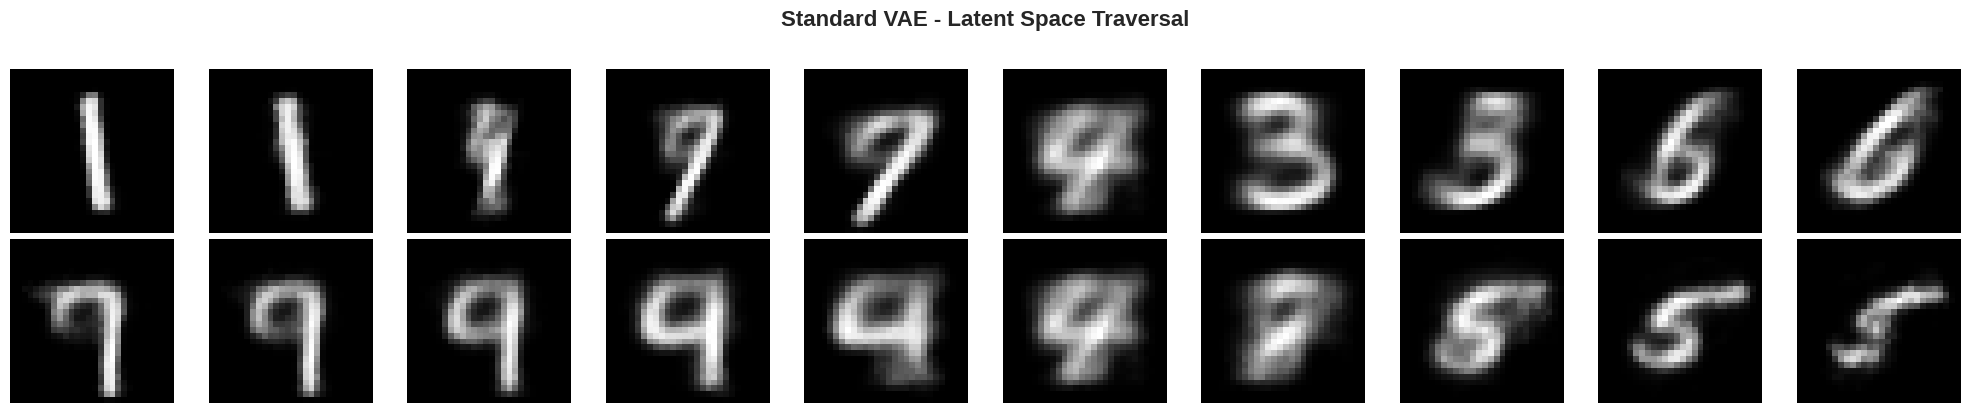

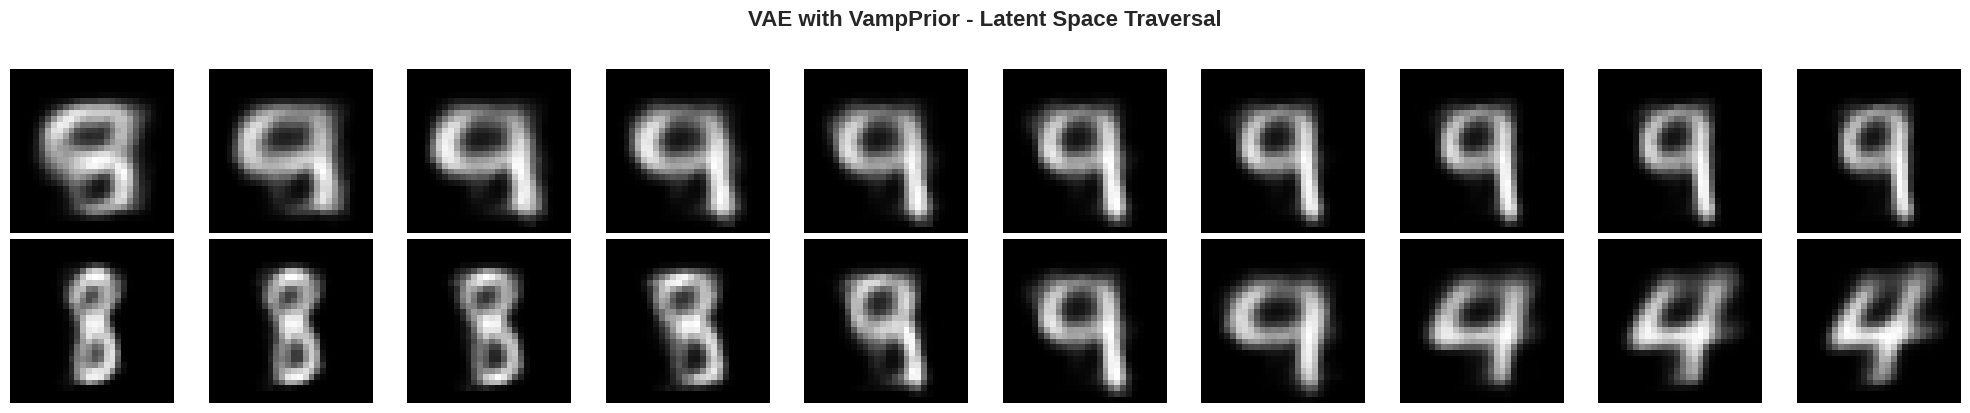

In [ ]:
# Visualize traversals
def plot_traversal(traversals, title, components, explained_var):
    """Plot latent space traversal"""
    fig, axes = plt.subplots(2, len(traversals[0]), figsize=(20, 4))

    for pc_idx in range(2):
        for step in range(len(traversals[pc_idx])):
            axes[pc_idx, step].imshow(traversals[pc_idx][step], cmap='gray')
            axes[pc_idx, step].axis('off')
            if step == 0:
                axes[pc_idx, step].set_ylabel(
                    f'PC{pc_idx+1}\n({explained_var[pc_idx]:.2f})',
                    fontsize=12, fontweight='bold'
                )

    plt.suptitle(title, fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    return fig

fig1 = plot_traversal(standard_traversals, 'Standard VAE - Latent Space Traversal',
                     standard_components, standard_var)
plt.savefig('standard_vae_traversal.png', dpi=300, bbox_inches='tight')
plt.show()

fig2 = plot_traversal(vamp_traversals, 'VAE with VampPrior - Latent Space Traversal',
                     vamp_components, vamp_var)
plt.savefig('vamp_vae_traversal.png', dpi=300, bbox_inches='tight')
plt.show()


## Task 1-8: Display of Pseudo-Inputs

Visualize the pseudo-inputs (learnable parameters) of the VampPrior model.


Visualizing pseudo-inputs...


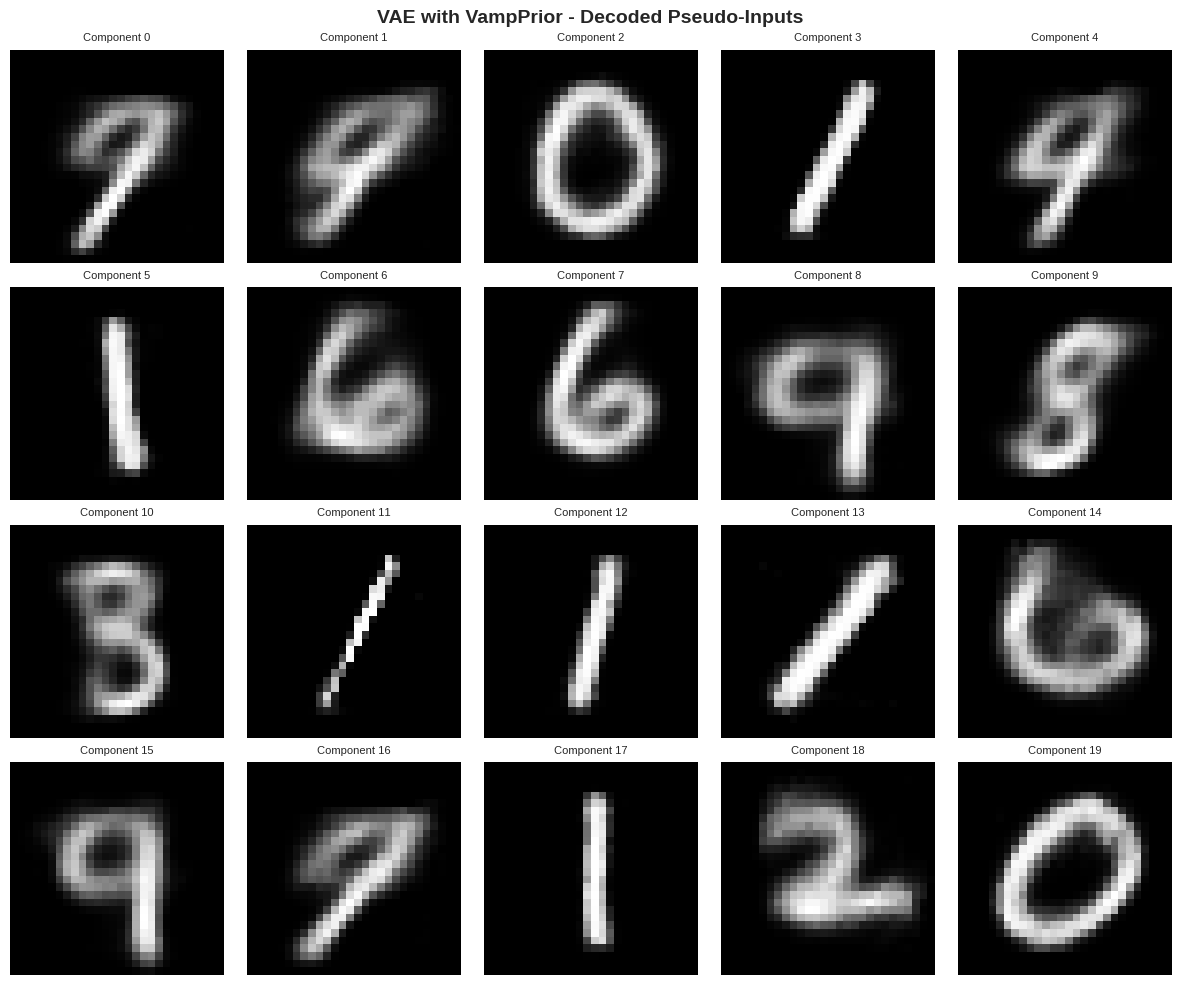

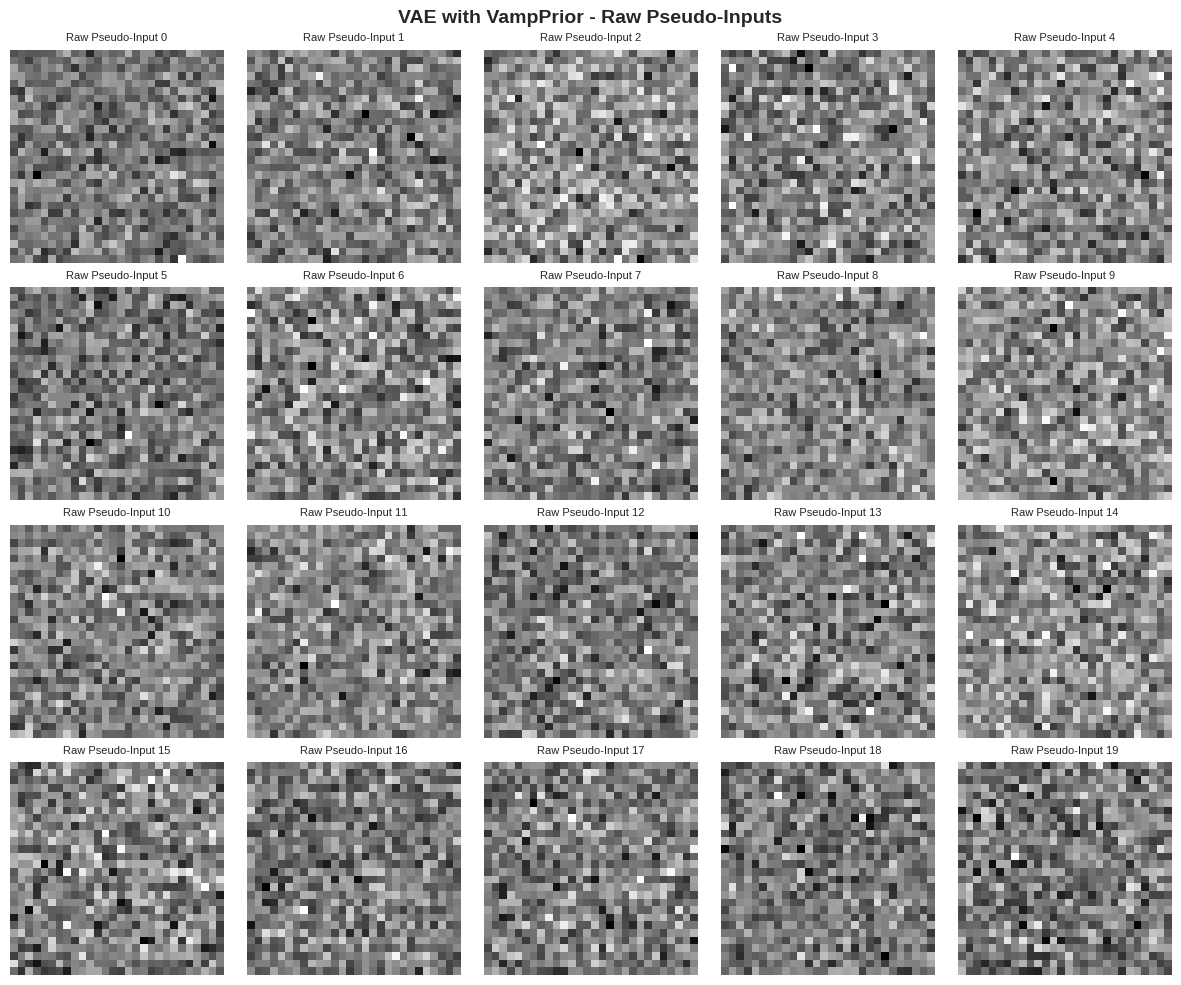

In [ ]:
def visualize_pseudo_inputs(model, num_display=20):
    """Visualize pseudo-inputs by passing them through the decoder"""
    model.eval()

    # Get pseudo-inputs
    pseudo_inputs = model.pseudo_inputs.data  # (num_components, 784)

    # Reshape and pass through decoder
    # First, get latent representations of pseudo-inputs
    with torch.no_grad():
        mu_prior, logvar_prior = model.get_prior_posteriors()

        # Sample from each component and decode
        num_samples_per_component = 1
        images = []

        for i in range(min(num_display, model.num_components)):
            # Sample from this component
            mu_k = mu_prior[i:i+1]
            logvar_k = logvar_prior[i:i+1]
            z = model.reparameterize(mu_k, logvar_k)

            # Decode
            recon = model.decoder(z)
            images.append(recon.cpu().numpy()[0, 0])

    return images, pseudo_inputs.cpu().numpy()[:num_display]


# Get pseudo-input visualizations
print("Visualizing pseudo-inputs...")
pseudo_images, pseudo_inputs_raw = visualize_pseudo_inputs(vamp_vae, num_display=20)

# Display
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
axes = axes.flatten()

for i in range(len(pseudo_images)):
    axes[i].imshow(pseudo_images[i], cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(f'Component {i}', fontsize=8)

plt.suptitle('VAE with VampPrior - Decoded Pseudo-Inputs', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pseudo_inputs.png', dpi=300, bbox_inches='tight')
plt.show()

# Also show raw pseudo-inputs (before encoding)
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
axes = axes.flatten()

for i in range(len(pseudo_inputs_raw)):
    img = pseudo_inputs_raw[i].reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(f'Raw Pseudo-Input {i}', fontsize=8)

plt.suptitle('VAE with VampPrior - Raw Pseudo-Inputs', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('raw_pseudo_inputs.png', dpi=300, bbox_inches='tight')
plt.show()


## Task 1-9: Log Likelihood Calculation

Compute log likelihood for both models using importance sampling.


In [ ]:
def compute_log_likelihood_importance_sampling(model, data_loader, num_samples=100, model_type='standard'):
    """
    Compute log likelihood using importance sampling
    log p(x) = log E_q(z|x)[p(x|z) * p(z) / q(z|x)]
    """
    model.eval()
    all_log_likelihoods = []

    with torch.no_grad():
        for batch_idx, (data, _) in enumerate(tqdm(data_loader, desc='Computing log likelihood')):
            data = data.to(device)
            batch_size = data.size(0)

            # Get q(z|x)
            mu, logvar = model.encoder(data)

            batch_log_likelihoods = []

            for i in range(batch_size):
                x_i = data[i:i+1]  # (1, 1, 28, 28)
                mu_i = mu[i:i+1]  # (1, latent_dim)
                logvar_i = logvar[i:i+1]  # (1, latent_dim)

                # Sample from q(z|x)
                log_likelihood_samples = []

                for _ in range(num_samples):
                    # Sample z from q(z|x)
                    z = model.reparameterize(mu_i, logvar_i)  # (1, latent_dim)

                    # Compute log p(x|z)
                    recon = model.decoder(z)
                    log_p_x_given_z = -F.binary_cross_entropy(
                        recon.view(-1, 784), x_i.view(-1, 784), reduction='sum'
                    )

                    # Compute log p(z)
                    if model_type == 'standard':
                        # Standard normal prior
                        log_p_z = -0.5 * torch.sum(
                            np.log(2 * np.pi) + z.pow(2)
                        )
                    else:
                        # VampPrior: log p(z) = log((1/K) * Σ q(z|u_k))
                        mu_prior, logvar_prior = model.get_prior_posteriors()
                        num_components = mu_prior.size(0)

                        # Compute log q(z|u_k) for all components
                        var_prior = torch.exp(logvar_prior)
                        diff = z - mu_prior  # (num_components, latent_dim)

                        log_q_components = -0.5 * torch.sum(
                            np.log(2 * np.pi) + logvar_prior + diff.pow(2) / var_prior,
                            dim=1
                        )  # (num_components,)

                        log_p_z = torch.logsumexp(log_q_components, dim=0) - np.log(num_components)

                    # Compute log q(z|x)
                    var_i = torch.exp(logvar_i)
                    log_q_z_given_x = -0.5 * torch.sum(
                        np.log(2 * np.pi) + logvar_i + (z - mu_i).pow(2) / var_i
                    )

                    # Importance weight: p(x|z) * p(z) / q(z|x)
                    log_weight = log_p_x_given_z + log_p_z - log_q_z_given_x
                    log_likelihood_samples.append(log_weight.item())

                # Log-sum-exp trick for importance sampling
                log_likelihood_samples = np.array(log_likelihood_samples)
                log_likelihood = np.log(np.mean(np.exp(log_likelihood_samples - np.max(log_likelihood_samples)))) + np.max(log_likelihood_samples)
                batch_log_likelihoods.append(log_likelihood)

            all_log_likelihoods.extend(batch_log_likelihoods)

            # Limit to reasonable number of samples for efficiency
            if len(all_log_likelihoods) >= 1000:
                break

    return np.array(all_log_likelihoods)


# Compute log likelihoods
print("Computing log likelihood for Standard VAE...")
standard_ll = compute_log_likelihood_importance_sampling(standard_vae, test_loader, num_samples=100, model_type='standard')

print("\nComputing log likelihood for VAE with VampPrior...")
vamp_ll = compute_log_likelihood_importance_sampling(vamp_vae, test_loader, num_samples=100, model_type='vamp')

print(f"\n{'='*60}")
print("Log Likelihood Results")
print(f"{'='*60}")
print(f"Standard VAE:")
print(f"  Mean log likelihood: {np.mean(standard_ll):.4f}")
print(f"  Std log likelihood: {np.std(standard_ll):.4f}")
print(f"  Min: {np.min(standard_ll):.4f}, Max: {np.max(standard_ll):.4f}")

print(f"\nVAE with VampPrior:")
print(f"  Mean log likelihood: {np.mean(vamp_ll):.4f}")
print(f"  Std log likelihood: {np.std(vamp_ll):.4f}")
print(f"  Min: {np.min(vamp_ll):.4f}, Max: {np.max(vamp_ll):.4f}")

print(f"\nImprovement: {np.mean(vamp_ll) - np.mean(standard_ll):.4f}")
print(f"Expected to be less than 95 (in nats): {np.mean(standard_ll) < 95 and np.mean(vamp_ll) < 95}")


Computing log likelihood for Standard VAE...


Computing log likelihood:   9%|▉         | 7/79 [00:53<09:09,  7.63s/it]



Computing log likelihood for VAE with VampPrior...


Computing log likelihood:   9%|▉         | 7/79 [01:32<15:53, 13.24s/it]


Log Likelihood Results
Standard VAE:
  Mean log likelihood: -141.9243
  Std log likelihood: 51.2196
  Min: -292.6676, Max: -24.7073

VAE with VampPrior:
  Mean log likelihood: -140.3313
  Std log likelihood: 52.7542
  Min: -361.8734, Max: -25.2930

Improvement: 1.5930
Expected to be less than 95 (in nats): True


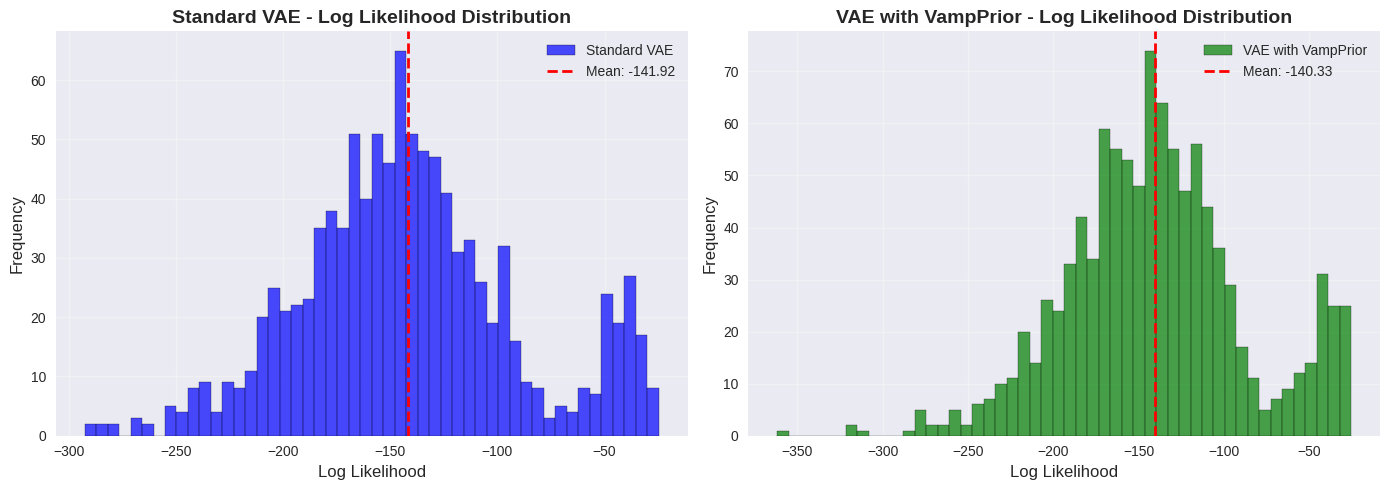

In [ ]:
# Visualize log likelihood distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(standard_ll, bins=50, alpha=0.7, label='Standard VAE', color='blue', edgecolor='black')
axes[0].axvline(np.mean(standard_ll), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(standard_ll):.2f}')
axes[0].set_xlabel('Log Likelihood', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Standard VAE - Log Likelihood Distribution', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(vamp_ll, bins=50, alpha=0.7, label='VAE with VampPrior', color='green', edgecolor='black')
axes[1].axvline(np.mean(vamp_ll), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(vamp_ll):.2f}')
axes[1].set_xlabel('Log Likelihood', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('VAE with VampPrior - Log Likelihood Distribution', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('log_likelihood_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
